In [1]:
!pip install nibabel tqdm matplotlib seaborn --quiet

In [2]:
import os
import time
import random
import numpy as np
import nibabel as nib
from glob import glob
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.checkpoint import checkpoint

sns.set_theme(style="whitegrid")

In [3]:
SEED = 42
IMG_SIZE = 128
EPOCHS = 10
BATCH_SIZE = 4
LR = 0.01
NUM_WORKERS = 4
PATIENCE = 6

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("CUDA:", torch.cuda.is_available())
print("GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"  GPU {i}:", torch.cuda.get_device_name(i))

CUDA: True
GPUs: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


In [4]:
DATA_ROOT = "/kaggle/input/datasets/awsaf49/brats20-dataset-training-validation"
TRAIN_PATH = os.path.join(DATA_ROOT, "BraTS2020_TrainingData", "MICCAI_BraTS2020_TrainingData")

all_cases = sorted(glob(os.path.join(TRAIN_PATH, "BraTS20_Training_*")))
all_cases = [c for c in all_cases if os.path.exists(f"{c}/{os.path.basename(c)}_seg.nii")]
print("Total cases:", len(all_cases))

Total cases: 368


In [5]:
def load_and_preprocess(path):
    cid = os.path.basename(path)

    def load_mod(mod):
        vol = nib.load(f"{path}/{cid}_{mod}.nii").get_fdata().astype(np.float32)
        mask = vol != 0
        if mask.sum() > 0:
            vol[mask] = (vol[mask] - vol[mask].mean()) / (vol[mask].std() + 1e-8)
        t = torch.from_numpy(vol).unsqueeze(0).unsqueeze(0)
        t = F.interpolate(
            t,
            size=(IMG_SIZE, IMG_SIZE, IMG_SIZE),
            mode="trilinear",
            align_corners=False,
        )
        return t.squeeze().numpy().astype(np.float16)

    flair = load_mod("flair")
    t1 = load_mod("t1")
    t1ce = load_mod("t1ce")
    t2 = load_mod("t2")

    seg = nib.load(f"{path}/{cid}_seg.nii").get_fdata().astype(np.float32)
    t = torch.from_numpy(seg).unsqueeze(0).unsqueeze(0)
    t = F.interpolate(t, size=(IMG_SIZE, IMG_SIZE, IMG_SIZE), mode="nearest")
    seg = t.squeeze().numpy()

    wt = (seg > 0).astype(np.float16)
    tc = ((seg == 1) | (seg == 4)).astype(np.float16)
    et = (seg == 4).astype(np.float16)

    image = np.stack([flair, t1, t1ce, t2], axis=0)
    label = np.stack([wt, tc, et], axis=0)
    return image, label


print("Preprocessing and caching all volumes to RAM...")
cache_start = time.time()
image_cache = {}
label_cache = {}

for path in tqdm(all_cases):
    img, lbl = load_and_preprocess(path)
    image_cache[path] = img
    label_cache[path] = lbl

print(
    f"Cache built. RAM used: {(sum(v.nbytes for v in image_cache.values()) + sum(v.nbytes for v in label_cache.values())) / 1e9:.2f} GB"
)

Preprocessing and caching all volumes to RAM...


  0%|          | 0/368 [00:00<?, ?it/s]

Cache built. RAM used: 10.80 GB


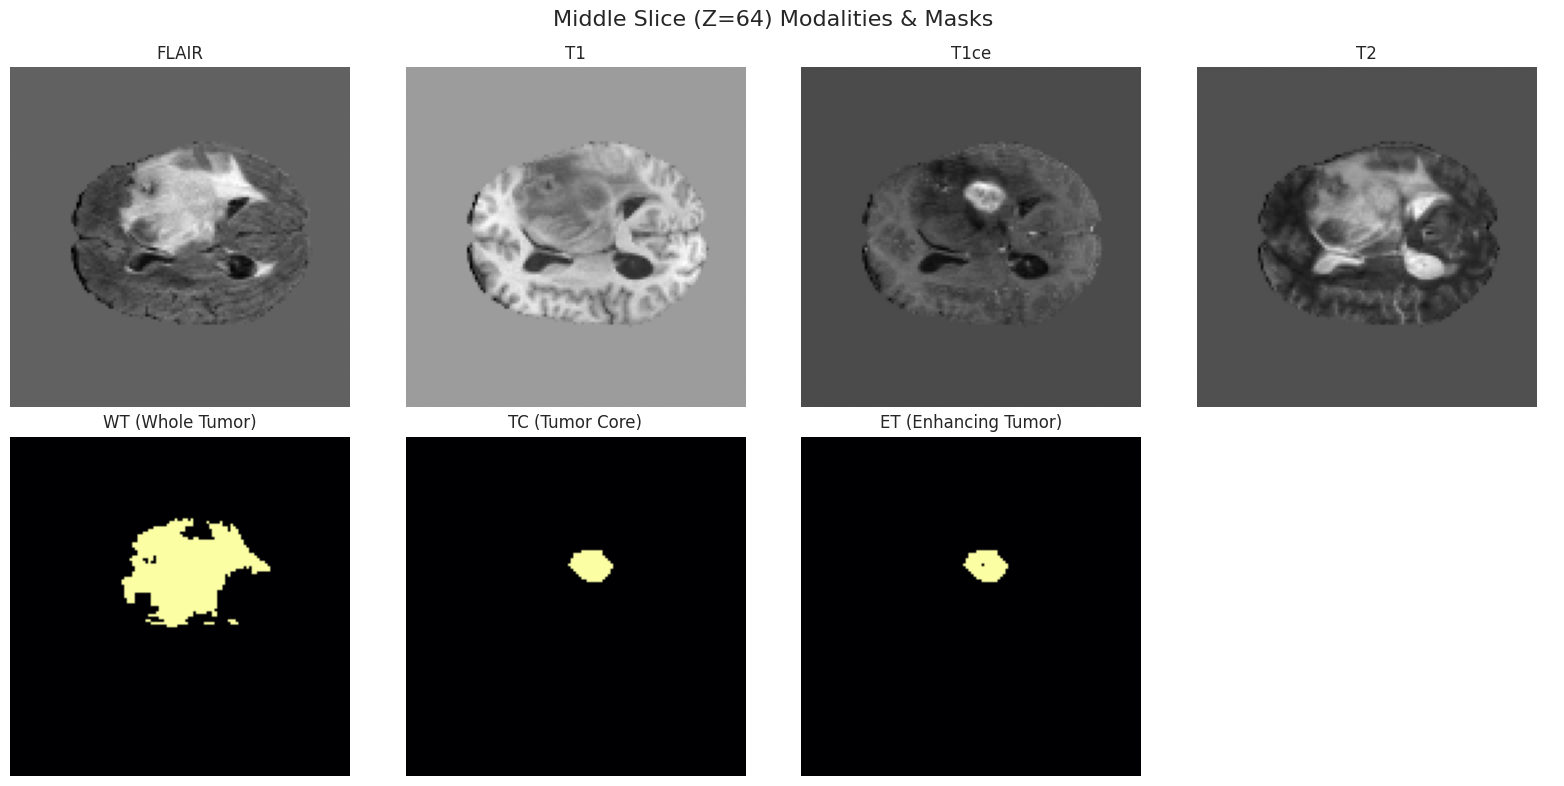

In [6]:
def visualize_sample(image, label, slice_idx=IMG_SIZE // 2):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(f"Middle Slice (Z={slice_idx}) Modalities & Masks", fontsize=16)

    mods = ["FLAIR", "T1", "T1ce", "T2"]
    for i in range(4):
        axes[0, i].imshow(image[i, :, :, slice_idx], cmap="gray")
        axes[0, i].set_title(mods[i])
        axes[0, i].axis("off")

    masks = ["WT (Whole Tumor)", "TC (Tumor Core)", "ET (Enhancing Tumor)"]
    for i in range(3):
        axes[1, i].imshow(label[i, :, :, slice_idx], cmap="inferno")
        axes[1, i].set_title(masks[i])
        axes[1, i].axis("off")

    axes[1, 3].axis("off")
    plt.tight_layout()
    plt.show()


sample_path = all_cases[0]
visualize_sample(image_cache[sample_path], label_cache[sample_path])

In [7]:
class BraTSDataset(Dataset):
    def __init__(self, cases, augment=False):
        self.cases = cases
        self.augment = augment

    def __len__(self):
        return len(self.cases)

    def __getitem__(self, idx):
        path = self.cases[idx]
        image = torch.from_numpy(image_cache[path].astype(np.float32))
        label = torch.from_numpy(label_cache[path].astype(np.float32))

        if self.augment:
            for ax in [1, 2, 3]:
                if random.random() < 0.5:
                    image = torch.flip(image, [ax])
                    label = torch.flip(label, [ax])
            image = image * torch.empty(4, 1, 1, 1).uniform_(0.9, 1.1)
            image = image + torch.empty(4, 1, 1, 1).uniform_(-0.1, 0.1)

        return image, label


train_ids, temp_ids = train_test_split(all_cases, test_size=0.3, random_state=SEED)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5, random_state=SEED)

train_loader = DataLoader(
    BraTSDataset(train_ids, augment=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True,
)
val_loader = DataLoader(
    BraTSDataset(val_ids, augment=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)
test_loader = DataLoader(
    BraTSDataset(test_ids, augment=False),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)

In [8]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, n_convs):
        super().__init__()
        layers = []
        ch = in_ch
        for _ in range(n_convs):
            layers += [
                nn.Conv3d(ch, out_ch, 3, padding=1, bias=False),
                nn.InstanceNorm3d(out_ch, affine=True),
                nn.PReLU(out_ch),
            ]
            ch = out_ch
        self.convs = nn.Sequential(*layers)
        self.proj = nn.Conv3d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        return self.convs(x) + self.proj(x)


class VNet3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = ResBlock(4, 16, 1)
        self.d1 = nn.Conv3d(16, 16, 2, stride=2, bias=False)
        self.e2 = ResBlock(16, 32, 1)
        self.d2 = nn.Conv3d(32, 32, 2, stride=2, bias=False)
        self.e3 = ResBlock(32, 64, 2)
        self.d3 = nn.Conv3d(64, 64, 2, stride=2, bias=False)
        self.b = ResBlock(64, 128, 2)
        self.u3 = nn.ConvTranspose3d(128, 64, 2, 2)
        self.r3 = ResBlock(128, 64, 2)
        self.u2 = nn.ConvTranspose3d(64, 32, 2, 2)
        self.r2 = ResBlock(64, 32, 1)
        self.u1 = nn.ConvTranspose3d(32, 16, 2, 2)
        self.r1 = ResBlock(32, 16, 1)
        self.out = nn.Conv3d(16, 3, 1)
        self.ds2 = nn.Conv3d(32, 3, 1)
        self.ds3 = nn.Conv3d(64, 3, 1)

    def forward(self, x):
        e1 = checkpoint(self.e1, x, use_reentrant=False)
        e2 = checkpoint(self.e2, self.d1(e1), use_reentrant=False)
        e3 = checkpoint(self.e3, self.d2(e2), use_reentrant=False)
        b = checkpoint(self.b, self.d3(e3), use_reentrant=False)
        d3 = checkpoint(self.r3, torch.cat([self.u3(b), e3], dim=1), use_reentrant=False)
        d2 = checkpoint(self.r2, torch.cat([self.u2(d3), e2], dim=1), use_reentrant=False)
        d1 = checkpoint(self.r1, torch.cat([self.u1(d2), e1], dim=1), use_reentrant=False)
        return self.out(d1), self.ds2(d2), self.ds3(d3)

In [9]:
def region_loss(logits, target):
    pred = torch.sigmoid(logits)
    inter = (pred * target).sum(dim=(0, 2, 3, 4))
    union = pred.sum(dim=(0, 2, 3, 4)) + target.sum(dim=(0, 2, 3, 4))
    dice = 1 - (2 * inter + 1e-6) / (union + 1e-6)
    bce = F.binary_cross_entropy_with_logits(logits, target)
    return dice.mean() + bce


def deep_supervision_loss(outputs, target):
    main, ds2, ds3 = outputs
    t2 = F.interpolate(target, size=ds2.shape[2:], mode="nearest")
    t3 = F.interpolate(target, size=ds3.shape[2:], mode="nearest")
    return (
        1.00 * region_loss(main, target) + 0.50 * region_loss(ds2, t2) + 0.25 * region_loss(ds3, t3)
    )


def dice_score(pred_bin, target_bin):
    inter = (pred_bin & target_bin).sum().float()
    return ((2 * inter + 1e-6) / (pred_bin.sum() + target_bin.sum() + 1e-6)).item()


def brats_metrics(pred_logits, target):
    pred = torch.sigmoid(pred_logits) > 0.5
    wt = dice_score(pred[:, 0], target[:, 0].bool())
    tc = dice_score(pred[:, 1], target[:, 1].bool())
    et = dice_score(pred[:, 2], target[:, 2].bool())
    return wt, tc, et

In [10]:
model = VNet3D()
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)
model = model.to(DEVICE)

optimizer = torch.optim.SGD(
    model.parameters(), lr=LR, momentum=0.99, nesterov=True, weight_decay=3e-5
)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lr_lambda=lambda ep: (1 - ep / EPOCHS) ** 0.9
)
scaler = torch.amp.GradScaler("cuda")

history = {
    "train_loss": [],
    "val_loss": [],
    "mean_dice": [],
    "wt_dice": [],
    "tc_dice": [],
    "et_dice": [],
}
best_mean_dice = 0.0
patience_counter = 0

In [11]:
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1} Train", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            outputs = model(x)
            loss = deep_supervision_loss(outputs, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item()

    scheduler.step()
    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0
    wt_scores, tc_scores, et_scores = [], [], []
    with torch.no_grad():
        for x, y in tqdm(val_loader, desc=f"Epoch {epoch+1} Val", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast("cuda"):
                outputs = model(x)
                loss = deep_supervision_loss(outputs, y)
            val_loss += loss.item()
            wt, tc, et = brats_metrics(outputs[0], y)
            wt_scores.append(wt)
            tc_scores.append(tc)
            et_scores.append(et)

    val_loss /= len(val_loader)
    wt_mean, tc_mean, et_mean = (
        np.mean(wt_scores),
        np.mean(tc_scores),
        np.mean(et_scores),
    )
    mean_dice = (wt_mean + tc_mean + et_mean) / 3

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["mean_dice"].append(mean_dice)
    history["wt_dice"].append(wt_mean)
    history["tc_dice"].append(tc_mean)
    history["et_dice"].append(et_mean)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Mean Dice: {mean_dice:.4f}"
    )

    if mean_dice > best_mean_dice:
        best_mean_dice = mean_dice
        patience_counter = 0
        torch.save(model.state_dict(), "best_model.pth")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

Epoch 1 Train:   0%|          | 0/64 [00:00<?, ?it/s]

Epoch 1 Val:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 1/10 | Train Loss: 1.9324 | Val Loss: 0.7989 | Mean Dice: 0.5990


Epoch 2 Train:   0%|          | 0/64 [00:00<?, ?it/s]

Epoch 2 Val:   0%|          | 0/14 [00:00<?, ?it/s]

...

Epoch 9 Val:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 9/10 | Train Loss: 0.4817 | Val Loss: 0.5143 | Mean Dice: 0.7407


Epoch 10 Train:   0%|          | 0/64 [00:00<?, ?it/s]

Epoch 10 Val:   0%|          | 0/14 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.4790 | Val Loss: 0.4698 | Mean Dice: 0.7664


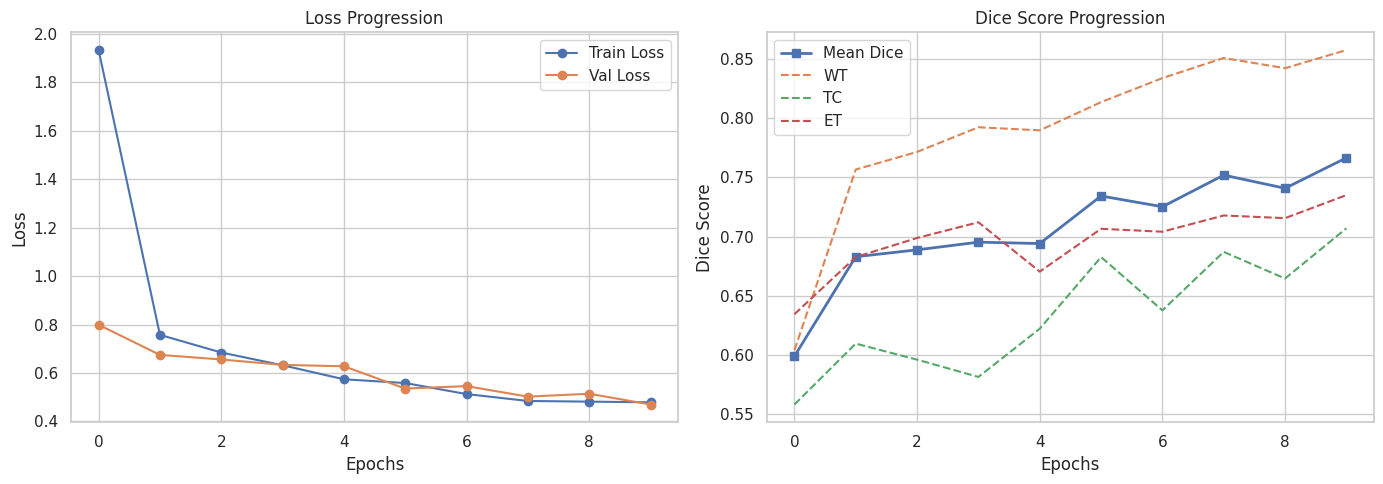

In [12]:
def plot_training_history(hist):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist["train_loss"], label="Train Loss", marker="o")
    axes[0].plot(hist["val_loss"], label="Val Loss", marker="o")
    axes[0].set_title("Loss Progression")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(hist["mean_dice"], label="Mean Dice", marker="s", linewidth=2)
    axes[1].plot(hist["wt_dice"], label="WT", linestyle="--")
    axes[1].plot(hist["tc_dice"], label="TC", linestyle="--")
    axes[1].plot(hist["et_dice"], label="ET", linestyle="--")
    axes[1].set_title("Dice Score Progression")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Dice Score")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


plot_training_history(history)

In [13]:
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
test_loss = 0.0
wt_scores, tc_scores, et_scores = [], [], []

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Test"):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.amp.autocast("cuda"):
            outputs = model(x)
            loss = deep_supervision_loss(outputs, y)
        test_loss += loss.item()
        wt, tc, et = brats_metrics(outputs[0], y)
        wt_scores.append(wt)
        tc_scores.append(tc)
        et_scores.append(et)

print(
    f"FINAL TEST RESULTS | Test Loss: {test_loss / len(test_loader):.4f} | Mean Dice: {np.mean([np.mean(wt_scores), np.mean(tc_scores), np.mean(et_scores)]):.4f}"
)

Test:   0%|          | 0/14 [00:00<?, ?it/s]

FINAL TEST RESULTS | Test Loss: 0.4847 | Mean Dice: 0.7658


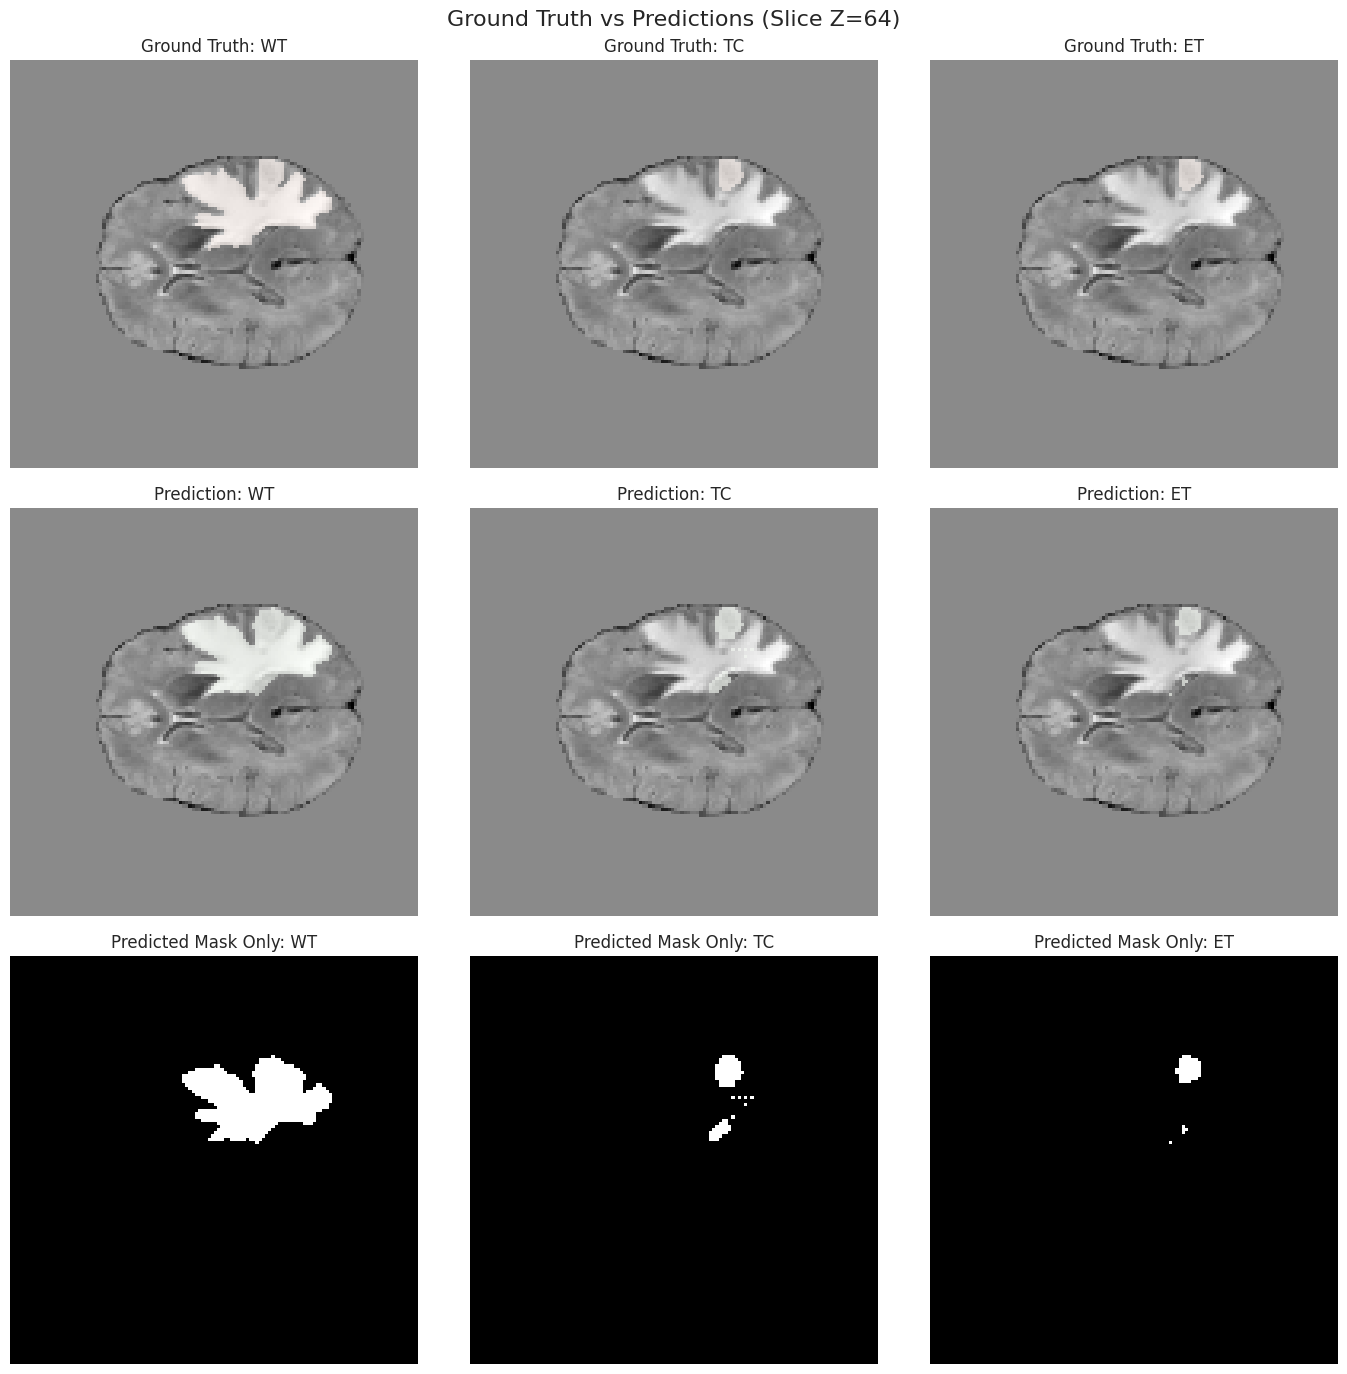

In [14]:
def visualize_predictions(model, loader, slice_idx=IMG_SIZE // 2):
    model.eval()
    x, y = next(iter(loader))
    with torch.no_grad():
        with torch.amp.autocast("cuda"):
            pred_logits, _, _ = model(x.to(DEVICE))
            preds = (torch.sigmoid(pred_logits) > 0.5).cpu().numpy()

    img = x[0].numpy()
    gt = y[0].numpy()
    pr = preds[0]

    fig, axes = plt.subplots(3, 3, figsize=(14, 14))
    fig.suptitle(f"Ground Truth vs Predictions (Slice Z={slice_idx})", fontsize=16)
    masks = ["WT", "TC", "ET"]

    for i in range(3):
        axes[0, i].imshow(img[0, :, :, slice_idx], cmap="gray")
        axes[0, i].imshow(
            np.ma.masked_where(gt[i, :, :, slice_idx] == 0, gt[i, :, :, slice_idx]),
            cmap="Reds",
            alpha=0.6,
        )
        axes[0, i].set_title(f"Ground Truth: {masks[i]}")
        axes[0, i].axis("off")

        axes[1, i].imshow(img[0, :, :, slice_idx], cmap="gray")
        axes[1, i].imshow(
            np.ma.masked_where(pr[i, :, :, slice_idx] == 0, pr[i, :, :, slice_idx]),
            cmap="Greens",
            alpha=0.6,
        )
        axes[1, i].set_title(f"Prediction: {masks[i]}")
        axes[1, i].axis("off")

        axes[2, i].imshow(pr[i, :, :, slice_idx], cmap="gray")
        axes[2, i].set_title(f"Predicted Mask Only: {masks[i]}")
        axes[2, i].axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, test_loader)